# DSCI 552 Homework 7

**Name:** Jingyu Zhang  
**GitHub Username:** jingyuz9-wq  
**USC ID:** 5744431585

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.exceptions import ConvergenceWarning
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from scipy.cluster.hierarchy import linkage, dendrogram

SEED = 552
warnings.filterwarnings("ignore", category=ConvergenceWarning)

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

### (a) Load the data and split 70/30

In [2]:
df = pd.read_csv("../data/Anuran Calls (MFCCs)/Frogs_MFCCs.csv")
LABELS = ["Family", "Genus", "Species"]
X = df.filter(like="MFCCs").values
Y = df[LABELS]

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=SEED)
print(X.shape, X_train.shape, X_test.shape)
for c in LABELS:
    print(df[c].value_counts().to_dict())

(7195, 22) (5036, 22) (2159, 22)
{'Leptodactylidae': 4420, 'Hylidae': 2165, 'Dendrobatidae': 542, 'Bufonidae': 68}
{'Adenomera': 4150, 'Hypsiboas': 1593, 'Ameerega': 542, 'Dendropsophus': 310, 'Leptodactylus': 270, 'Scinax': 148, 'Osteocephalus': 114, 'Rhinella': 68}
{'AdenomeraHylaedactylus': 3478, 'HypsiboasCordobae': 1121, 'AdenomeraAndre': 672, 'Ameeregatrivittata': 542, 'HypsiboasCinerascens': 472, 'HylaMinuta': 310, 'LeptodactylusFuscus': 270, 'ScinaxRuber': 148, 'OsteocephalusOophagus': 114, 'Rhinellagranulosa': 68}


### (b) i. Exact match and Hamming score / loss

Each instance has $L = 3$ labels (Family, Genus, Species). For $n$ test instances with true labels $y_{ij}$ and predictions $\hat y_{ij}$:

- **Exact match ratio:** $\frac{1}{n}\sum_{i} \mathbb{1}[\hat y_{ij} = y_{ij}\ \forall j]$, the fraction of instances whose three labels are all correct. It is the strictest measure.
- **Hamming loss:** $\frac{1}{nL}\sum_{i}\sum_{j} \mathbb{1}[\hat y_{ij} \ne y_{ij}]$, the fraction of individual labels that are wrong. It gives partial credit.
- **Hamming score:** $1 - $ Hamming loss, the fraction of labels predicted correctly. (For binary label vectors, Sorower also defines a Jaccard-type Hamming score; with multi-class labels the natural version is 1 − loss.)
- **Hamming distance** of one instance is $\sum_j \mathbb{1}[\hat y_{ij} \ne y_{ij}] \in \{0, 1, 2, 3\}$; its average over instances is $L$ times the Hamming loss.

In [3]:
def multilabel_scores(Y_true, Y_pred):
    wrong = np.asarray(Y_true) != np.asarray(Y_pred)
    return {"exact_match": (~wrong.any(axis=1)).mean(),
            "hamming_loss": wrong.mean(),
            "hamming_score": 1 - wrong.mean()}

def fit_binary_relevance(make_search):
    models, pred = {}, pd.DataFrame(index=Y_test.index)
    for c in LABELS:
        gs = make_search().fit(X_train, Y_train[c])
        models[c] = gs
        pred[c] = gs.predict(X_test)
    return models, pred

def summarize(models, pred, params):
    rows = {c: {**{p: models[c].best_params_[p] for p in params},
                "cv_acc": models[c].best_score_,
                "test_acc": (pred[c] == Y_test[c]).mean()} for c in LABELS}
    display(pd.DataFrame(rows).T)
    s = multilabel_scores(Y_test, pred)
    print({k: round(v, 4) for k, v in s.items()})
    return s

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

### (b) ii. Gaussian-kernel SVM, one-versus-all

Following the footnote, I trained on the full training set at extreme values of $C$ and $\gamma$ first. Training accuracy stays above 70% for $C \ge 0.1$ and $\gamma \in [0.1, 10]$, so the grid is $C \in \{10^{-1}, \dots, 10^{4}\}$ and $\sigma \in \{0.2, 0.4, \dots, 2.0\}$ with $\gamma = 1/(2\sigma^2)$. Both raw and standardized features are tried.

In [4]:
sigmas = np.arange(0.2, 2.01, 0.2)
rbf_grid = {"svm__estimator__C": 10.0 ** np.arange(-1, 5),
            "svm__estimator__gamma": 1 / (2 * sigmas ** 2)}

def rbf_search(scale):
    steps = [("scale", StandardScaler())] if scale else []
    pipe = Pipeline(steps + [("svm", OneVsRestClassifier(SVC(kernel="rbf")))])
    return lambda: GridSearchCV(pipe, rbf_grid, cv=cv, scoring="accuracy", n_jobs=-1)

params = ["svm__estimator__C", "svm__estimator__gamma"]
results = {}
rbf_raw, pred_rbf_raw = fit_binary_relevance(rbf_search(False))
results["RBF SVM (raw)"] = summarize(rbf_raw, pred_rbf_raw, params)

,svm__estimator__C,svm__estimator__gamma,cv_acc,test_acc
Family,100.0,3.125,0.994045,0.992126
Genus,10.0,3.125,0.991463,0.988884
Species,100.0,3.125,0.990665,0.987957


{'exact_match': np.float64(0.987), 'hamming_loss': np.float64(0.0103), 'hamming_score': np.float64(0.9897)}


In [5]:
rbf_std, pred_rbf_std = fit_binary_relevance(rbf_search(True))
results["RBF SVM (standardized)"] = summarize(rbf_std, pred_rbf_std, params)

,svm__estimator__C,svm__estimator__gamma,cv_acc,test_acc
Family,10.0,0.125,0.989477,0.988421
Genus,10.0,0.125,0.987689,0.987957
Species,10.0,0.125,0.987089,0.986568


{'exact_match': np.float64(0.9833), 'hamming_loss': np.float64(0.0124), 'hamming_score': np.float64(0.9876)}


**Results.** With raw features the selected parameters are $\gamma = 3.125$ ($\sigma = 0.4$) and $C = 100$ for Family and Species, and $C = 10$ for Genus. On the test set this gives an exact match ratio of 0.9870 and a Hamming loss of 0.0103. After standardization, CV selects $\gamma = 0.125$ ($\sigma = 2.0$) and $C = 10$ for all three labels. The test results are almost the same (exact match 0.9833, Hamming loss 0.0124). The MFCCs are already on a common $[-1, 1]$ scale, so standardization makes little difference here. The selected $\sigma$ for standardized features sits on the edge of the grid; standardization inflates the low-variance coefficients, which calls for a wider kernel.

### (b) iii. L1-penalized linear SVM

`LinearSVC(penalty="l1")` is one-versus-rest by default. Training accuracy is above 70% for $C \ge 10^{-2}$, so $C \in \{10^{-2}, 10^{-1.5}, \dots, 10^{2}\}$.

In [6]:
l1_grid = {"svm__C": np.logspace(-2, 2, 9)}

def l1_search(smote):
    svm = ("svm", LinearSVC(penalty="l1", dual=False, max_iter=10000))
    steps = [("scale", StandardScaler())] + ([("smote", SMOTE(random_state=SEED))] if smote else [])
    pipe = Pipeline(steps + [svm])
    return lambda: GridSearchCV(pipe, l1_grid, cv=cv, scoring="accuracy", n_jobs=-1)

l1, pred_l1 = fit_binary_relevance(l1_search(False))
results["L1 SVM"] = summarize(l1, pred_l1, ["svm__C"])

,svm__C,cv_acc,test_acc
Family,1.000000,0.937849,0.933302
Genus,3.162278,0.954729,0.952293
Species,1.000000,0.958101,0.956461


{'exact_match': np.float64(0.9176), 'hamming_loss': np.float64(0.0526), 'hamming_score': np.float64(0.9474)}


**Results.** The L1 linear SVM selects $C = 1$ for Family and Species and $C \approx 3.16$ for Genus. Test exact match is 0.9176 and Hamming loss is 0.0526. This is clearly worse than the Gaussian-kernel SVM because the classes are not linearly separable in the MFCC space. In exchange, the model is sparse and much cheaper to train.

### (b) iv. L1-penalized SVM with SMOTE

SMOTE is placed inside the pipeline so that synthetic samples are generated only from the training folds during CV.

In [7]:
l1_sm, pred_l1_sm = fit_binary_relevance(l1_search(True))
results["L1 SVM + SMOTE"] = summarize(l1_sm, pred_l1_sm, ["svm__C"])

,svm__C,cv_acc,test_acc
Family,31.622777,0.922758,0.913386
Genus,1.000000,0.917197,0.910607
Species,0.100000,0.955123,0.950903


{'exact_match': np.float64(0.8615), 'hamming_loss': np.float64(0.075), 'hamming_score': np.float64(0.925)}


In [8]:
pd.DataFrame(results).T.round(4)

,exact_match,hamming_loss,hamming_score
RBF SVM (raw),0.9870,0.0103,0.9897
RBF SVM (standardized),0.9833,0.0124,0.9876
L1 SVM,0.9176,0.0526,0.9474
L1 SVM + SMOTE,0.8615,0.0750,0.9250


**Results and conclusions.** With SMOTE, test exact match drops to 0.8615 and Hamming loss rises to 0.0750. Per-label accuracy falls for Family and Genus, and Species stays about the same. This is expected. Oversampling the rare classes (e.g. Bufonidae, 68 instances) shifts the linear boundaries toward the majority classes. That can improve recall on the small classes, but it lowers overall accuracy, which is the metric being optimized and reported here.

Overall:
- The Gaussian-kernel SVM is the best classifier, with about 98.5% of test instances having all three labels correct. Raw and standardized features perform about the same.
- The L1-penalized linear SVM loses about 7 points of exact match.
- SMOTE does not help in terms of exact match or Hamming loss.
- Exact match is always lower than the Hamming score because one wrong label out of three makes the whole instance count as a miss.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Choosing $k$

$k$ is chosen by the average silhouette over $k \in \{2, \dots, 50\}$ ($k = 1$ is excluded since the silhouette is undefined for a single cluster). Each Monte Carlo run uses a different k-means initialization, so the selected $k$, the clusters and the Hamming distance can change from run to run. The figure shows the silhouette curve for the first run.

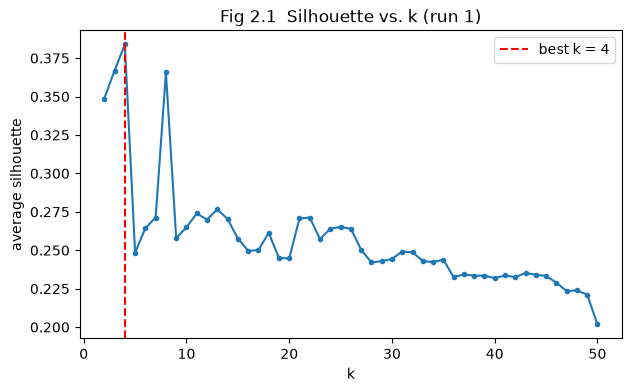

In [9]:
Xall, Yall = df.filter(like="MFCCs").values, df[LABELS]
K_RANGE = range(2, 51)

def silhouette_curve(seed):
    return [silhouette_score(Xall, KMeans(k, random_state=seed).fit_predict(Xall))
            for k in K_RANGE]

sil0 = silhouette_curve(0)
k0 = K_RANGE[int(np.argmax(sil0))]

plt.figure(figsize=(7, 4))
plt.plot(list(K_RANGE), sil0, "o-", ms=3)
plt.axvline(k0, color="r", ls="--", label=f"best k = {k0}")
plt.xlabel("k")
plt.ylabel("average silhouette")
plt.title("Fig 2.1  Silhouette vs. k (run 1)")
plt.legend()
plt.show()

### (b) Majority labels in each cluster (run 1)

In [10]:
def cluster_majority(labels):
    maj = Yall.groupby(labels).agg(lambda s: s.mode()[0])
    return maj, maj.loc[labels].set_axis(Yall.index)

km0 = KMeans(k0, random_state=0).fit_predict(Xall)
maj0, Yhat0 = cluster_majority(km0)
maj0.assign(size=pd.Series(km0).value_counts().sort_index())

,Family,Genus,Species,size
0,Leptodactylidae,Adenomera,AdenomeraHylaedactylus,3584
1,Hylidae,Hypsiboas,HypsiboasCordobae,2216
2,Hylidae,Hypsiboas,HypsiboasCinerascens,663
3,Leptodactylidae,Adenomera,AdenomeraAndre,732


### (c) Hamming distance, score and loss over 50 Monte Carlo runs

In [11]:
def one_run(seed):
    sil = silhouette_curve(seed)
    k = K_RANGE[int(np.argmax(sil))]
    _, Yhat = cluster_majority(KMeans(k, random_state=seed).fit_predict(Xall))
    wrong = (Yall.values != Yhat.values)
    return {"k": k, "hamming_distance": wrong.sum(axis=1).mean(),
            "hamming_loss": wrong.mean(), "hamming_score": 1 - wrong.mean()}

mc = pd.DataFrame(Parallel(n_jobs=-1)(delayed(one_run)(s) for s in range(50)))
print(mc["k"].value_counts().to_dict())
mc.drop(columns="k").agg(["mean", "std"]).round(4)

{4: 25, 3: 12, 6: 6, 2: 6, 5: 1}


,hamming_distance,hamming_loss,hamming_score
mean,0.7187,0.2396,0.7604
std,0.1309,0.0436,0.0436


**Results.** Over the 50 runs, the silhouette criterion chose $k = 4$ most often (25 runs), followed by $k = 3$ (12 runs), with $k \in \{2, 5, 6\}$ in the rest. In run 1, the four clusters are dominated by the four largest species (table in (b)), so the six smaller species are never the majority label of any cluster.

Over the 50 runs, the average Hamming distance is $0.719 \pm 0.131$ (mean ± std), the Hamming loss is $0.240 \pm 0.044$, and the Hamming score is $0.760 \pm 0.044$. On average, about 0.7 of the three labels per instance disagree with the cluster's majority triplet. Most of the errors come from Species and Genus, since a handful of clusters cannot represent 10 species.

## 3. ISLR 12.6.2

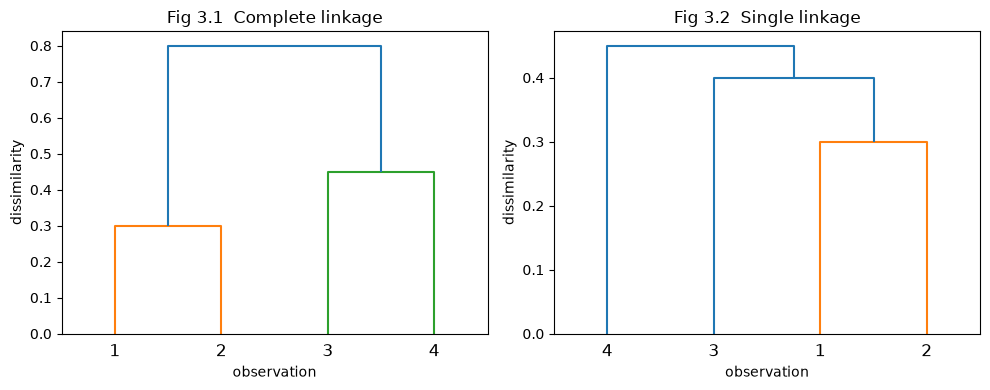

In [12]:
diss = np.array([[0, 0.3, 0.4, 0.7],
                 [0.3, 0, 0.5, 0.8],
                 [0.4, 0.5, 0, 0.45],
                 [0.7, 0.8, 0.45, 0]])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, method in zip(axes, ["complete", "single"]):
    dendrogram(linkage(diss[np.triu_indices(4, 1)], method=method), labels=[1, 2, 3, 4], ax=ax)
    ax.set_xlabel("observation")
    ax.set_ylabel("dissimilarity")
    ax.set_title(f"Fig 3.{1 if method == 'complete' else 2}  {method.capitalize()} linkage")
plt.tight_layout()
plt.show()

### (a) Complete linkage

Observations 1 and 2 fuse first at height 0.3. The complete-linkage distances are then $d(\{1,2\},3) = \max(0.4, 0.5) = 0.5$, $d(\{1,2\},4) = \max(0.7, 0.8) = 0.8$ and $d(3,4) = 0.45$, so 3 and 4 fuse at 0.45. Finally $\{1,2\}$ and $\{3,4\}$ fuse at $\max(0.4, 0.5, 0.7, 0.8) = 0.8$ (Fig 3.1).

### (b) Single linkage

Observations 1 and 2 fuse at 0.3. Then $d(\{1,2\},3) = \min(0.4, 0.5) = 0.4$, $d(\{1,2\},4) = 0.7$ and $d(3,4) = 0.45$, so 3 joins $\{1,2\}$ at 0.4. Observation 4 joins last at $\min(0.7, 0.8, 0.45) = 0.45$ (Fig 3.2).

### (c) Cutting the complete-linkage dendrogram into two clusters

The clusters are $\{1, 2\}$ and $\{3, 4\}$.

### (d) Cutting the single-linkage dendrogram into two clusters

The clusters are $\{1, 2, 3\}$ and $\{4\}$.

### (e) An equivalent dendrogram

The two branches at any fusion can be swapped without changing the meaning of the dendrogram. For the complete-linkage dendrogram in (a), swapping the leaves within each fusion gives the leaf order 2, 1, 4, 3, with 2 and 1 fusing at 0.3, 4 and 3 fusing at 0.45, and the two pairs fusing at 0.8. This dendrogram looks different but represents exactly the same clustering.

## References

1. Anuran Calls (MFCCs) Data Set, UCI Machine Learning Repository. https://archive.ics.uci.edu/ml/datasets/Anuran+Calls+%28MFCCs%29
2. M. S. Sorower, *A Literature Survey on Algorithms for Multi-label Learning*, Oregon State University, 2010.
3. G. James, D. Witten, T. Hastie, R. Tibshirani, *An Introduction to Statistical Learning*, 2nd ed., Springer, 2021.
4. scikit-learn documentation: `SVC`, `LinearSVC`, `OneVsRestClassifier`, `GridSearchCV`, `KMeans`, `silhouette_score`. https://scikit-learn.org
5. imbalanced-learn documentation: `SMOTE`. https://imbalanced-learn.org